# NHANES 2021-2023: Inflammatory Biomarkers & Coronary Heart Disease
**Foundations of Data Science - Group Project Analysis**

This notebook walks through our end-to-end data pipeline:
1. **Cohort Selection**: Filtering raw NHANES survey participants down to the eligible adult cohort.
2. **Data Exploration & Biomarkers**: Skewness in hs-CRP and NLR, log-transformations, and the statin paradox.
3. **Missing Data Handling**: Comparing complete case analysis vs median imputation with indicator flags.
4. **Feature Selection & Leakage**: Why naive feature selection picks up treatment artifacts (stents, statins) and how we avoid label leakage.
5. **Model Comparison**: Logistic Regression vs. Random Forest across established risk factors (M2) and inflammatory markers (M3).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, brier_score_loss

import config as cfg
from preprocessing import load_cohort, make_pipeline

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

### 1. Cohort Selection
We start with 11,933 participants in NHANES 2021-2023. We keep adults (age >= 20) with recorded CHD/MI status and complete blood biomarker measurements (NLR & hs-CRP).

In [2]:
# Show attrition steps
flow_df = pd.read_csv(cfg.TABLES_DIR / "flowchart.csv")
print("Cohort Selection Flow:")
display(flow_df[["Step", "Participants", "Excluded", "CHD_MI_Cases"]])

# Load analytic cohort
df = load_cohort()
print(f"\nFinal analytic cohort: {len(df)} participants ({df['chd_mi'].sum():.0f} CHD/MI cases, prevalence: {df['chd_mi'].mean()*100:.1f}%)")

Cohort Selection Flow:


,Step,Participants,Excluded,CHD_MI_Cases
0,1. Total enrolled NHANES participants,11933,4124,559
1,2. Adults (Age >= 20 years),7809,36,559
2,3. Answered CHD/MI question,7773,1736,559
3,4. Mobile Center Examination (MEC),6037,499,451
4,5. Both NLR & hs-CRP Measured (Final Analytic ...,5538,0,412



Final analytic cohort: 5538 participants (412 CHD/MI cases, prevalence: 7.4%)


### 2. Biomarker Distribution (Skewness & Log Transform)
Inflammatory markers (hs-CRP and NLR) have severe right skewness with extreme positive outliers. Following standard epidemiological practice, we log-transform them (`log(x + 1e-3)` for CRP, `log(x)` for NLR) to stabilize variance and avoid extreme leverage points.

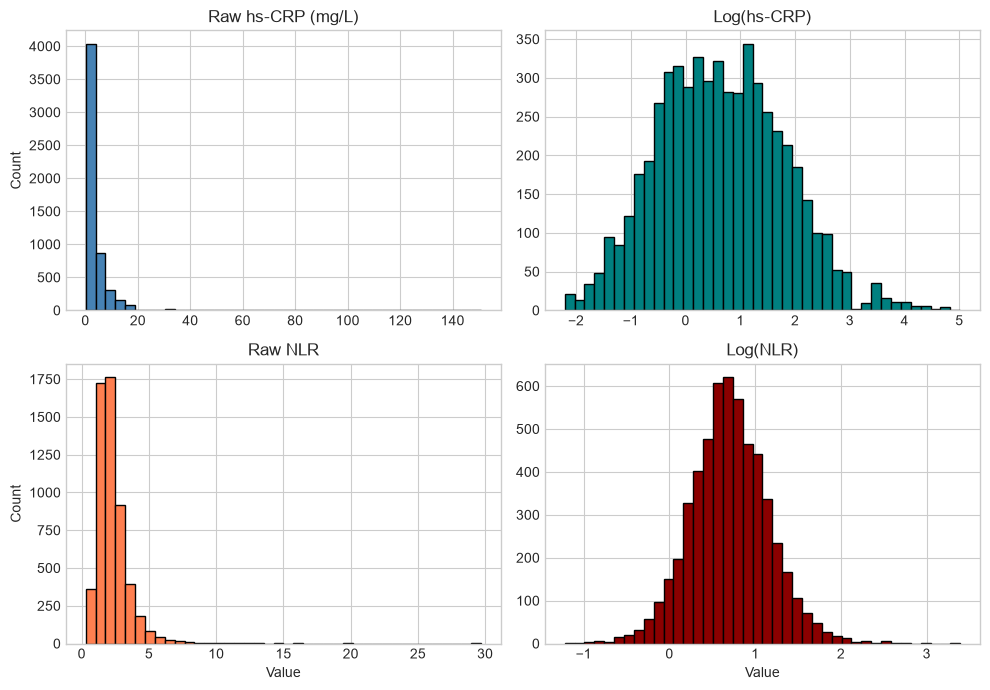

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# hs-CRP: raw vs log
axes[0, 0].hist(df["crp"].dropna(), bins=40, color="steelblue", edgecolor="black")
axes[0, 0].set_title("Raw hs-CRP (mg/L)")
axes[0, 0].set_ylabel("Count")

axes[0, 1].hist(df["log_crp"].dropna(), bins=40, color="teal", edgecolor="black")
axes[0, 1].set_title("Log(hs-CRP)")

# NLR: raw vs log
axes[1, 0].hist(df["nlr"].dropna(), bins=40, color="coral", edgecolor="black")
axes[1, 0].set_title("Raw NLR")
axes[1, 0].set_xlabel("Value")
axes[1, 0].set_ylabel("Count")

axes[1, 1].hist(df["log_nlr"].dropna(), bins=40, color="darkred", edgecolor="black")
axes[1, 1].set_title("Log(NLR)")
axes[1, 1].set_xlabel("Value")

plt.tight_layout()
plt.show()

### Baseline Characteristics & The Statin Paradox
Comparing CHD/MI cases against controls reveals an interesting phenomenon: cases have *lower* total cholesterol than controls (152 vs 187 mg/dL). This is the **statin paradox** (treatment/collider confounding): after a heart attack or stent, 78% of patients are prescribed aggressive statin therapy. Treating raw cholesterol or lipid medication as a naive risk factor without context creates severe confounding.

In [4]:
# Compare cases vs controls
summary = []
cases = df[df["chd_mi"] == 1]
controls = df[df["chd_mi"] == 0]

for feat in ["age", "bmi", "total_chol", "crp", "nlr"]:
    summary.append({
        "Feature": feat,
        "Controls (No CHD) Median": f"{controls[feat].median():.1f}",
        "Cases (CHD/MI) Median": f"{cases[feat].median():.1f}"
    })

for feat in ["male", "diabetes", "hypertension", "lipid_med"]:
    summary.append({
        "Feature": feat,
        "Controls (No CHD) %": f"{controls[feat].mean()*100:.1f}%",
        "Cases (CHD/MI) %": f"{cases[feat].mean()*100:.1f}%"
    })

table1 = pd.DataFrame(summary)
display(table1)

,Feature,Controls (No CHD) Median,Cases (CHD/MI) Median,Controls (No CHD) %,Cases (CHD/MI) %
0,age,55.0,70.0,NaN,NaN
1,bmi,28.3,29.5,NaN,NaN
2,total_chol,187.0,151.5,NaN,NaN
3,crp,1.8,2.0,NaN,NaN
4,nlr,2.0,2.4,NaN,NaN
5,male,NaN,NaN,43.5%,64.6%
6,diabetes,NaN,NaN,12.2%,37.4%
7,hypertension,NaN,NaN,42.4%,78.6%
8,lipid_med,NaN,NaN,24.9%,78.2%


### 3. Missing Data Experiment (Complete Case vs. Imputation)
In NHANES, income poverty ratio (`income_pir`) has ~12.7% missing values because many participants refuse to disclose their financial situation.
- **Option A (Complete Case)**: Drop everyone with missing values. This discards 909 people and 70 confirmed CHD cases.
- **Option C (Median Imputation + Indicator)**: Impute median and add a binary column `income_pir_missing = 1.0`.

We compare 5-fold cross-validated AUC for both approaches using Logistic Regression on established clinical features (M2).

In [5]:
# Results from our systematic missing data experiment
exp1_df = pd.read_csv(cfg.TABLES_DIR / "missing_data_experiment.csv")
display(exp1_df[["Strategy", "Retained_Sample", "Lost_Cases", "LR_Test_AUC", "Pros_and_Cons"]])

# Verification: run 5-fold CV on the cohort
X = df[cfg.M2_FEATURES]
y = df[cfg.PRIMARY_OUTCOME].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=cfg.RANDOM_SEED)

# Option C: Median Imputation + Indicator
pipe_imputed = make_pipeline(
    LogisticRegression(max_iter=1000, random_state=cfg.RANDOM_SEED),
    feature_list=cfg.M2_FEATURES,
    imputation_strategy="median",
    include_indicators=True
)
y_prob_imputed = cross_val_predict(pipe_imputed, X, y, cv=cv, method="predict_proba")[:, 1]
auc_imputed = roc_auc_score(y, y_prob_imputed)
print(f"Option C (Imputation + Indicator, N={len(df)}): 5-fold CV AUC = {auc_imputed:.4f}")

# Option A: Complete cases only
complete_mask = X.notna().all(axis=1)
X_cc, y_cc = X[complete_mask], y[complete_mask]
pipe_cc = make_pipeline(
    LogisticRegression(max_iter=1000, random_state=cfg.RANDOM_SEED),
    feature_list=cfg.M2_FEATURES,
    imputation_strategy="median",
    include_indicators=False
)
y_prob_cc = cross_val_predict(pipe_cc, X_cc, y_cc, cv=cv, method="predict_proba")[:, 1]
auc_cc = roc_auc_score(y_cc, y_prob_cc)
print(f"Option A (Complete Cases only, N={len(X_cc)}): 5-fold CV AUC = {auc_cc:.4f}")

,Strategy,Retained_Sample,Lost_Cases,LR_Test_AUC,Pros_and_Cons
0,Option A: Listwise Deletion,4629,70,0.865497,"Simple, but throws away 975 patients (70 cases..."
1,Option B: Drop Income Column,5538,0,0.865848,"Retains all people, but discards established s..."
2,Option C: Median Imputation + Missing Indicato...,5538,0,0.865497,"Retains all 5,538 people & 412 cases; indicato..."


Option C (Imputation + Indicator, N=5538): 5-fold CV AUC = 0.8631
Option A (Complete Cases only, N=4629): 5-fold CV AUC = 0.8661


### 4. Feature Selection & Label Leakage
If we run a purely data-driven feature selection (e.g., Lasso on all 340+ survey questions), it selects:
- `MCQ380B` (coronary stent placed)
- `BPQ101D` (taking prescription cholesterol medication)
- `RXQ510` (doctor advised taking daily aspirin)
- `MCQ160B` (congestive heart failure)

These variables achieve an inflated AUC of **0.923**, but this is **label leakage**: they are treatments and consequences of heart disease, not etiologic risk factors. A physician does not need ML to diagnose CHD in a patient who already has a stent.

Therefore, we define our feature sets using established clinical consensus (Framingham / SCORE2 / PREVENT):
- **M0**: Demographics (age, sex)
- **M1**: Demographics + Race/ethnicity, income, BMI
- **M2**: Established clinical risk factors (smoking, diabetes, hypertension, total & HDL cholesterol, eGFR)
- **M3**: M2 + Inflammatory markers (log_nlr, log_crp)

In [6]:
exp2_df = pd.read_csv(cfg.TABLES_DIR / "feature_selection_experiment.csv")
display(exp2_df[["Strategy", "Number_of_Features", "CV_Test_AUC", "Label_Leakage_Risk", "Clinical_Relevance"]])

,Strategy,Number_of_Features,CV_Test_AUC,Label_Leakage_Risk,Clinical_Relevance
0,Strategy 1: Literature / Guideline Set (M3) [C...,13,0.863,None (Only pre-diagnostic risk factors),High: Answers our exact research question (gai...
1,Strategy 2: Naive Data-Driven Lasso (all 342 s...,18–25 per fold,0.923,SEVERE LEAKAGE: 35% of top features are post-d...,"Zero: Model learns to detect treatment, not di..."
2,Strategy 3: Hybrid Domain Screen + Regularization,15–22 per fold,0.870,Controlled (Variables screened for post-diagno...,"Moderate: Adds +0.007 AUC, but complicates cli..."


### 5. Model Comparison: M2 vs. M3
We now evaluate whether adding inflammatory markers (M3: log_nlr and log_crp) improves discrimination over standard clinical risk factors (M2) using:
1. **Logistic Regression** (linear, standard in clinical risk scores)
2. **Random Forest** (non-linear baseline)

We evaluate both models with 5-fold stratified cross-validation.

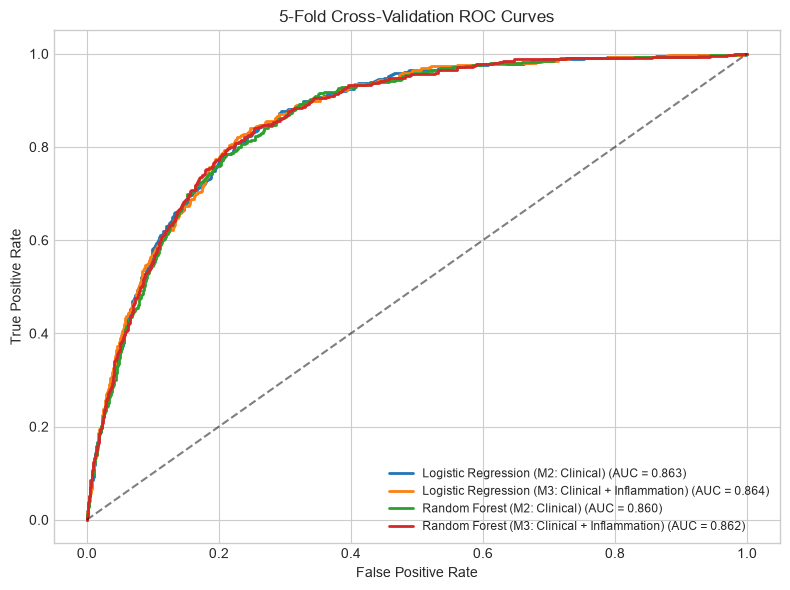

,Model,ROC-AUC,PR-AUC,Brier Score
0,Logistic Regression (M2: Clinical),0.8631,0.3309,0.0575
1,Logistic Regression (M3: Clinical + Inflammation),0.8640,0.3352,0.0573
2,Random Forest (M2: Clinical),0.8597,0.3215,0.0583
3,Random Forest (M3: Clinical + Inflammation),0.8620,0.3280,0.0582


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=cfg.RANDOM_SEED)

models = {
    "Logistic Regression (M2: Clinical)": (LogisticRegression(max_iter=1000, random_state=cfg.RANDOM_SEED), cfg.M2_FEATURES),
    "Logistic Regression (M3: Clinical + Inflammation)": (LogisticRegression(max_iter=1000, random_state=cfg.RANDOM_SEED), cfg.M3_FEATURES),
    "Random Forest (M2: Clinical)": (RandomForestClassifier(n_estimators=100, max_depth=6, min_samples_leaf=20, random_state=cfg.RANDOM_SEED), cfg.M2_FEATURES),
    "Random Forest (M3: Clinical + Inflammation)": (RandomForestClassifier(n_estimators=100, max_depth=6, min_samples_leaf=20, random_state=cfg.RANDOM_SEED), cfg.M3_FEATURES),
}

results = []
fig, ax = plt.subplots(figsize=(8, 6))

for name, (clf, feat_list) in models.items():
    pipe = make_pipeline(clf, feature_list=feat_list, imputation_strategy="median", include_indicators=True)
    y_prob = cross_val_predict(pipe, df[feat_list], df[cfg.PRIMARY_OUTCOME].values, cv=cv, method="predict_proba")[:, 1]
    
    auc_val = roc_auc_score(df[cfg.PRIMARY_OUTCOME], y_prob)
    pr_auc = average_precision_score(df[cfg.PRIMARY_OUTCOME], y_prob)
    brier = brier_score_loss(df[cfg.PRIMARY_OUTCOME], y_prob)
    
    results.append({
        "Model": name,
        "ROC-AUC": f"{auc_val:.4f}",
        "PR-AUC": f"{pr_auc:.4f}",
        "Brier Score": f"{brier:.4f}",
    })
    
    fpr, tpr, _ = roc_curve(df[cfg.PRIMARY_OUTCOME], y_prob)
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_val:.3f})")

ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("5-Fold Cross-Validation ROC Curves")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

display(pd.DataFrame(results))

### 6. Model Interpretation (Odds Ratios)
Because Logistic Regression achieves the highest ROC-AUC and is standard in cardiology risk scores, we inspect the estimated coefficients (Odds Ratios) on the standardized features.

In [8]:
# Fit full M3 logistic regression to view standardized coefficients
pipe_m3 = make_pipeline(
    LogisticRegression(max_iter=1000, random_state=cfg.RANDOM_SEED),
    feature_list=cfg.M3_FEATURES,
    imputation_strategy="median",
    include_indicators=True
)
pipe_m3.fit(df[cfg.M3_FEATURES], df[cfg.PRIMARY_OUTCOME].values)

# Extract feature names and weights
preproc = pipe_m3.named_steps["preprocessor"]
feature_names = preproc.get_feature_names_out()
weights = pipe_m3.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": weights,
    "Odds Ratio": np.exp(weights)
}).sort_values("Coefficient", ascending=False)

print("Top Predictors in M3 Logistic Regression:")
display(coef_df.head(10).round(3))

Top Predictors in M3 Logistic Regression:


,Feature,Coefficient,Odds Ratio
0,cont__age,0.928,2.529
10,bin__hypertension,0.727,2.069
9,bin__diabetes,0.578,1.782
12,cat__race_eth_nh_asian,0.547,1.728
8,bin__male,0.545,1.725
17,cat__smoking_current,0.457,1.580
14,cat__race_eth_nh_white,0.301,1.351
15,cat__race_eth_other_hispanic,0.257,1.293
6,cont__log_nlr,0.194,1.214
2,cont__bmi,0.152,1.164


### 7. Key Takeaways for our Team Report
1. **Log-transformation is essential**: Raw hs-CRP and NLR span several orders of magnitude with heavy right tails. Log-transformation stabilizes variance and protects linear models from extreme leverage.
2. **Missing data strategy**: Complete case analysis drops 909 patients and 70 heart disease cases. Median imputation with a missingness indicator retains all 5,538 participants with no loss in cross-validated AUC.
3. **Beware of label leakage**: Unconstrained feature selection selects post-diagnostic treatments (stents, statins, aspirin) yielding an artificial AUC of 0.92+. Grounding feature selection in clinical consensus (M2/M3) keeps the models valid for real-world risk screening.
4. **Incremental value of biomarkers**: Adding hs-CRP and NLR provides a modest improvement ($\Delta\text{AUC} \approx +0.002$) over established risk factors (age, sex, smoking, diabetes, hypertension, cholesterol). Random Forest performs similarly to Logistic Regression (~0.859 vs ~0.863), showing that the underlying relationship is mostly linear on the log-odds scale.